# Credit Card Fraud Analysis
### Uncovering when fraud happens, which amounts are risky and where the money is lost
**Tools:** Python (pandas, NumPy), SQL (SQLite), Matplotlib/Seaborn &nbsp;|&nbsp; **Dataset:** [Kaggle – Credit Card Fraud Detection (ULB)](https://www.kaggle.com/datasets/mlg-ulb/creditcardfraud)

---

## Executive Summary

**Goal:** analyse 283,726 card transactions to find where fraud happens, how much it costs and which hours and amounts need the most attention.

**Key findings**

| |  |
|---|---|
| **Scale** | **473 frauds (0.167%)** worth **€58.6k** over 2 days – about **236 fraud cases per day**. |
| **Timing** | Night hours (00:00–06:59, assuming the recording starts near midnight) carry **10% of transactions but 26% of fraud**, the night fraud rate is **3.3× the daytime rate**, peaking at **02:00 (8.7× average)**. |
| **Amounts** | **36% of frauds are ≤ €1** (consistent with card testing), while transactions **> €250 cause 74% of the money lost**. |
| **Signals** | Four anonymized columns (**V17, V14, V12, V10**) differ between fraud and legitimate activity far more than amount or hour do. |
| **Alert rules** | Two simple rules beat checking everything. Night + €1 or less finds **1 fraud every 49 checks**, compared with 1 in 600. Night + over €250 covers **€5.92 of fraud per check**, compared with €0.21. |


**Recommendation:** start with two targeted alert rules: night + €1 or less to spot stolen cards early and night + over €250 to protect the most money per check.

**Skills demonstrated:** data cleaning & quality checks · feature engineering · exploratory analysis · SQL (CTEs, window functions) · KPI design · data visualisation · testing business rules · business recommendations · dashboard-ready exports.

---

## 1. Business Context & Questions

A card issuer's fraud team wants to understand **where fraud happens, how much it costs and which hours and amounts need the most attention**.

This analysis answers six business questions:

| # | Business question | Section |
|---|---|---|
| Q1 | How big is the fraud problem (volume, rate, money lost)? | 4 |
| Q2 | Do fraudulent transactions look different in **amount**? | 5 |
| Q3 | **When** does fraud happen – are some hours riskier? | 6 |
| Q4 | Which transaction **amount bands** carry the highest risk and the biggest losses? | 7 |
| Q5 | Which (anonymized) columns look most different for fraud? | 8 |
| Q6 | A fraud team can't check every transaction. **Which simple alert rule should it start with?** | 10 |

**About the data:** 2 days of transactions by European cardholders (September 2013).
`Time` = seconds since the first transaction, `Amount` = transaction value, `Class` = 1 for fraud.
`V1`–`V28` are anonymized (PCA-transformed) features released this way for confidentiality, so they can be compared but not named.

## 2. Setup

In [34]:
import os
import sqlite3
import warnings
warnings.filterwarnings('ignore')

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import matplotlib.ticker as mticker
import seaborn as sns

RANDOM_STATE = 42

# Consistent visual style for the whole report
LEGIT_C, FRAUD_C, ACCENT_C, GREY_C = '#4C72B0', '#D1495B', '#EDAE49', '#8C8C8C'
sns.set_theme(style='whitegrid', font_scale=1.0)
plt.rcParams.update({'figure.dpi': 110, 'axes.spines.top': False, 'axes.spines.right': False,
                     'axes.titleweight': 'bold', 'axes.titlesize': 12})
pd.set_option('display.float_format', lambda v: f'{v:,.2f}')

os.makedirs('figures', exist_ok=True)
os.makedirs('outputs', exist_ok=True)

def money(v):
    return f'€{v:,.0f}'

def save(fig, name):
    fig.savefig(f'figures/{name}.png', bbox_inches='tight')

## 3. Data Loading & Data Quality Checks



In [37]:
CANDIDATE_PATHS = ['creditcard.csv', 'data/creditcard.csv', '/content/creditcard.csv']
DATA_PATH = next((p for p in CANDIDATE_PATHS if os.path.exists(p)), None)
assert DATA_PATH, 'creditcard.csv not found - download it from Kaggle and put it next to this notebook.'

raw = pd.read_csv(DATA_PATH)
print(f'Loaded {DATA_PATH}: {raw.shape[0]:,} rows x {raw.shape[1]} columns')
raw.head()

Loaded creditcard.csv: 284,807 rows x 31 columns


,Time,V1,V2,V3,V4,V5,V6,V7,V8,V9,...,V21,V22,V23,V24,V25,V26,V27,V28,Amount,Class
0,0.00,-1.36,-0.07,2.54,1.38,-0.34,0.46,0.24,0.10,0.36,...,-0.02,0.28,-0.11,0.07,0.13,-0.19,0.13,-0.02,149.62,0
1,0.00,1.19,0.27,0.17,0.45,0.06,-0.08,-0.08,0.09,-0.26,...,-0.23,-0.64,0.10,-0.34,0.17,0.13,-0.01,0.01,2.69,0
2,1.00,-1.36,-1.34,1.77,0.38,-0.50,1.80,0.79,0.25,-1.51,...,0.25,0.77,0.91,-0.69,-0.33,-0.14,-0.06,-0.06,378.66,0
3,1.00,-0.97,-0.19,1.79,-0.86,-0.01,1.25,0.24,0.38,-1.39,...,-0.11,0.01,-0.19,-1.18,0.65,-0.22,0.06,0.06,123.50,0
4,2.00,-1.16,0.88,1.55,0.40,-0.41,0.10,0.59,-0.27,0.82,...,-0.01,0.80,-0.14,0.14,-0.21,0.50,0.22,0.22,69.99,0


In [39]:
# Data quality report: one row per check
quality = pd.DataFrame({
    'Check': ['Rows', 'Columns', 'Missing values (all cells)', 'Exact duplicate rows',
              'Duplicate rows that are fraud', 'Negative amounts', 'Zero-value transactions',
              'Time span (hours)'],
    'Result': [len(raw), raw.shape[1], int(raw.isna().sum().sum()), int(raw.duplicated().sum()),
               int(raw[raw.duplicated()]['Class'].sum()), int((raw['Amount'] < 0).sum()),
               int((raw['Amount'] == 0).sum()), round(raw['Time'].max() / 3600, 1)]
})
quality['Result'] = quality['Result'].map(lambda v: f'{v:,.0f}' if float(v).is_integer() else f'{v:,.1f}')
quality

,Check,Result
0,Rows,"284,807"
1,Columns,31
2,Missing values (all cells),0
3,Exact duplicate rows,"1,081"
4,Duplicate rows that are fraud,19
5,Negative amounts,0
6,Zero-value transactions,"1,825"
7,Time span (hours),48


**Data quality findings**
- No missing values and no negative amounts.
- A small number of **exact duplicate rows** exist (identical on all 31 columns). They may be logging duplicates, although the data cannot confirm this. They are removed to avoid double-counting; this assumption drops 19 fraud-labelled rows.
- Some transactions have an amount of **0** (likely card-verification checks). They are kept, but tracked as their own amount band because they behave differently.

In [42]:
df = raw.drop_duplicates().reset_index(drop=True)
df['Class'] = df['Class'].astype(int)
print(f'Removed {len(raw) - len(df):,} duplicate rows -> {len(df):,} clean transactions')

Removed 1,081 duplicate rows -> 283,726 clean transactions


### Feature engineering for analysis
- **`Hour`** – hour of day derived from `Time` (seconds since the first transaction). The dataset does not state the clock time of the first transaction. The number of transactions falls sharply overnight, which suggests hour 0 is close to midnight, but this is an inference and every "night" finding below relies on it.
- **`Day`** – day 1 or day 2 of the recording window.
- **`Amount_Band`** – business-friendly value bands.
- **`Label`** – readable class name for charts.

In [45]:
df['Hour'] = (df['Time'] // 3600 % 24).astype(int)
df['Day']  = (df['Time'] // 86400 + 1).astype(int)

band_edges  = [-0.01, 0, 1, 10, 50, 100, 250, 500, 1000, np.inf]
band_labels = ['€0', '€0-1', '€1-10', '€10-50', '€50-100', '€100-250', '€250-500', '€500-1k', '€1k+']
df['Amount_Band'] = pd.cut(df['Amount'], bins=band_edges, labels=band_labels)
df['Label'] = df['Class'].map({0: 'Legitimate', 1: 'Fraud'})

df[['Time', 'Hour', 'Day', 'Amount', 'Amount_Band', 'Label']].sample(5, random_state=RANDOM_STATE)

,Time,Hour,Day,Amount,Amount_Band,Label
104279,"69,195.00",19,1,56.42,€50-100,Legitimate
133849,"80,769.00",22,1,9.82,€1-10,Legitimate
42456,"41,182.00",11,1,46.08,€10-50,Legitimate
875,666.00,0,1,3.58,€1-10,Legitimate
262310,"160,870.00",20,2,2.84,€1-10,Legitimate


## 4. Q1 – How big is the fraud problem? (KPIs)

In [48]:
fraud = df[df['Class'] == 1]
legit = df[df['Class'] == 0]

kpis = {
    'Total transactions'         : f"{len(df):,}",
    'Fraudulent transactions'    : f"{len(fraud):,}",
    'Fraud rate (by count)'      : f"{len(fraud) / len(df):.3%}",
    'Total transaction value'    : money(df['Amount'].sum()),
    'Fraud value (loss exposure)': money(fraud['Amount'].sum()),
    'Fraud rate (by value)'      : f"{fraud['Amount'].sum() / df['Amount'].sum():.3%}",
    'Avg fraud transaction'      : f"€{fraud['Amount'].mean():,.2f}",
    'Avg legitimate transaction' : f"€{legit['Amount'].mean():,.2f}",
    'Fraud cases per day'        : f"{len(fraud) / df['Day'].nunique():,.0f}",
}
kpi_df = pd.DataFrame.from_dict(kpis, orient='index', columns=['Value'])
kpi_df

,Value
Total transactions,"283,726"
Fraudulent transactions,473
Fraud rate (by count),0.167%
Total transaction value,"€25,102,002"
Fraud value (loss exposure),"€58,591"
Fraud rate (by value),0.233%
Avg fraud transaction,€123.87
Avg legitimate transaction,€88.41
Fraud cases per day,236


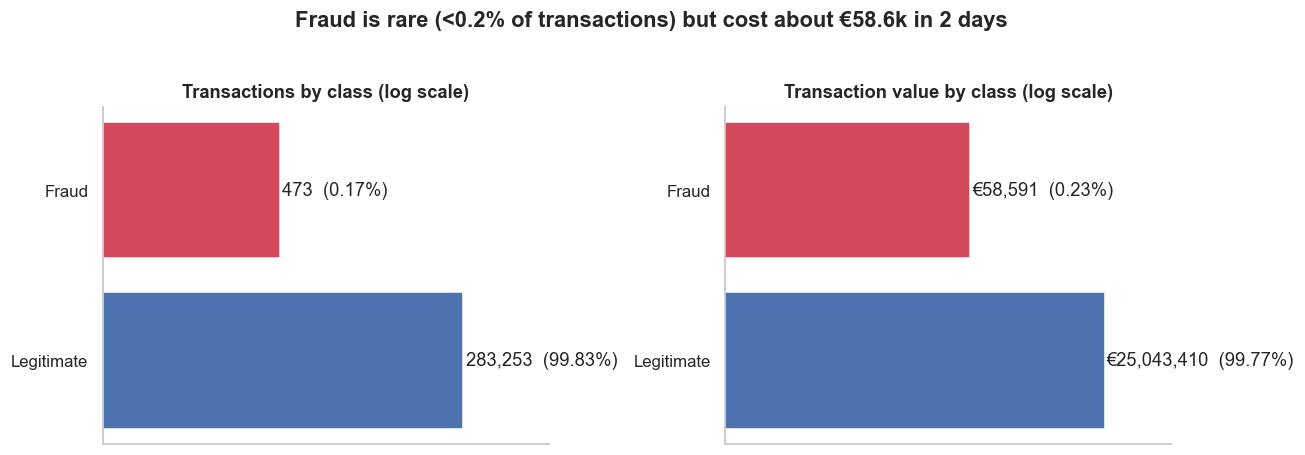

In [50]:
fig, axes = plt.subplots(1, 2, figsize=(12, 4))

counts = df['Label'].value_counts().reindex(['Legitimate', 'Fraud'])
values = df.groupby('Label')['Amount'].sum().reindex(['Legitimate', 'Fraud'])

for ax, series, title, fmt in [
    (axes[0], counts, 'Transactions by class', lambda v: f'{v:,.0f}'),
    (axes[1], values, 'Transaction value by class', money)]:
    bars = ax.barh(series.index, series.values, color=[LEGIT_C, FRAUD_C])
    ax.set_xscale('log')
    ax.set_title(title + ' (log scale)')
    for b, v in zip(bars, series.values):
        share = v / series.sum()
        ax.text(v * 1.1, b.get_y() + b.get_height() / 2, f'{fmt(v)}  ({share:.2%})', va='center')
    ax.set_xlim(1, series.max() * 20)
    ax.xaxis.set_major_formatter(mticker.NullFormatter())
    ax.grid(False)

fig.suptitle('Fraud is rare (<0.2% of transactions) but cost about €58.6k in 2 days',
             fontweight='bold', y=1.03)
plt.tight_layout(); save(fig, '01_kpi_overview'); plt.show()

**Insight:** fraud is a needle-in-a-haystack problem. Fewer than 2 in 1,000 transactions are fraudulent, so a team that simply "trusts everything" would look 99.8% accurate while missing every case. That is why the rest of this analysis focuses on **when fraud happens and where the money is lost**.

## 5. Q2 – Do fraudulent transactions look different in amount?

In [53]:
amount_stats = df.groupby('Label')['Amount'].describe(percentiles=[.25, .5, .75, .9, .99])
amount_stats = amount_stats[['count', 'mean', '25%', '50%', '75%', '90%', '99%', 'max']]
amount_stats.columns = ['Count', 'Mean', 'P25', 'Median', 'P75', 'P90', 'P99', 'Max']
amount_stats.loc[['Legitimate', 'Fraud']]

,Count,Mean,P25,Median,P75,P90,P99,Max
Label,,,,,,,,
Legitimate,"283,253.00",88.41,5.67,22.00,77.46,203.00,"1,018.06","25,691.16"
Fraud,473.00,123.87,1.00,9.82,105.89,348.65,"1,364.14","2,125.87"


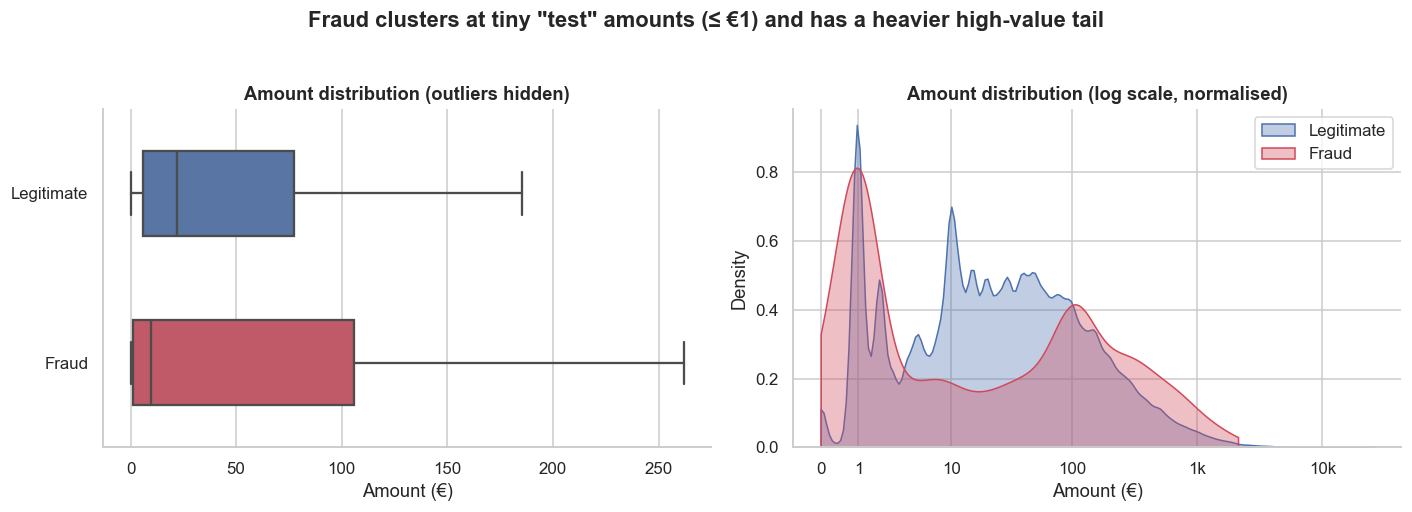

36.2% of fraud transactions are €1 or less (vs 10.6% of legitimate ones).


In [56]:
fig, axes = plt.subplots(1, 2, figsize=(13, 4.5))

sns.boxplot(data=df, x='Amount', y='Label', order=['Legitimate', 'Fraud'],
            palette=[LEGIT_C, FRAUD_C], showfliers=False, ax=axes[0], width=0.5)
axes[0].set_title('Amount distribution (outliers hidden)')
axes[0].set_xlabel('Amount (€)'); axes[0].set_ylabel('')

for label, color in [('Legitimate', LEGIT_C), ('Fraud', FRAUD_C)]:
    sub = np.log10(df.loc[df['Label'] == label, 'Amount'] + 1)
    sns.kdeplot(sub, ax=axes[1], color=color, fill=True, alpha=0.35, bw_adjust=0.6, cut=0, label=label)
axes[1].set_title('Amount distribution (log scale, normalised)')
axes[1].set_xlabel('Amount (€)')
axes[1].set_xticks(np.log10(np.array([0, 1, 10, 100, 1000, 10000]) + 1))
axes[1].set_xticklabels(['0', '1', '10', '100', '1k', '10k'])
axes[1].set_ylabel('Density'); axes[1].legend()

fig.suptitle('Fraud clusters at tiny "test" amounts (≤ €1) and has a heavier high-value tail', fontweight='bold', y=1.03)
plt.tight_layout(); save(fig, '02_amount_distribution'); plt.show()

share_under_1 = (fraud['Amount'] <= 1).mean()
print(f'{share_under_1:.1%} of fraud transactions are €1 or less (vs {(legit["Amount"] <= 1).mean():.1%} of legitimate ones).')

In [57]:
small = pd.DataFrame({
    'Transactions €1 or less': [(fraud['Amount'] <= 1).sum(), (legit['Amount'] <= 1).sum()],
    'All transactions': [len(fraud), len(legit)]
}, index=['Fraud', 'Legitimate'])
small['Share %'] = (small['Transactions €1 or less'] / small['All transactions'] * 100).round(1)
small

,Transactions €1 or less,All transactions,Share %
Fraud,171,473,36.20
Legitimate,30160,283253,10.60


**Insight:** the median fraud is *smaller* than the median legitimate transaction, but the distribution is two-humped: a large cluster of **≤ €1 transactions** (consistent with fraudsters "testing" a stolen card) and a long tail of larger purchases that drive most of the money lost. Amount alone is therefore a weak filter – a rule like "flag everything above €X" would miss most cases.

## 6. Q3 – When does fraud happen?

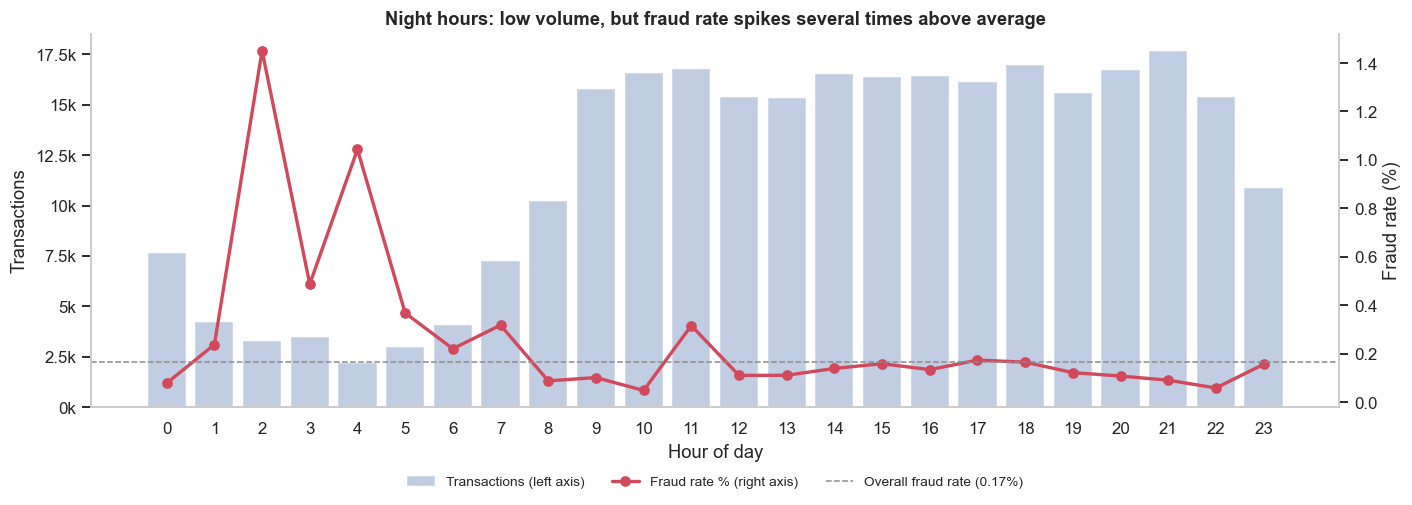

In [60]:
hourly = (df.groupby('Hour')
            .agg(Transactions=('Class', 'size'), Fraud_Cases=('Class', 'sum'),
                 Fraud_Value=('Amount', lambda s: s[df.loc[s.index, 'Class'] == 1].sum()))
            .assign(Fraud_Rate_pct=lambda t: t['Fraud_Cases'] / t['Transactions'] * 100))

overall_rate = df['Class'].mean() * 100

fig, ax1 = plt.subplots(figsize=(13, 4.8))
ax1.bar(hourly.index, hourly['Transactions'], color=LEGIT_C, alpha=0.35, label='Transactions (left axis)')
ax1.set_xlabel('Hour of day'); ax1.set_ylabel('Transactions')
ax1.yaxis.set_major_formatter(mticker.FuncFormatter(lambda v, _: f'{v/1000:g}k'))
ax1.set_xticks(range(24)); ax1.grid(False)

ax2 = ax1.twinx()
ax2.plot(hourly.index, hourly['Fraud_Rate_pct'], color=FRAUD_C, marker='o', lw=2.2, label='Fraud rate % (right axis)')
ax2.axhline(overall_rate, color=GREY_C, ls='--', lw=1, label=f'Overall fraud rate ({overall_rate:.2f}%)')
ax2.set_ylabel('Fraud rate (%)'); ax2.grid(False)
ax2.spines['right'].set_visible(True)

h1, l1 = ax1.get_legend_handles_labels(); h2, l2 = ax2.get_legend_handles_labels()
ax1.legend(h1 + h2, l1 + l2, loc='upper center', bbox_to_anchor=(0.5, -0.15), ncol=3, fontsize=9, frameon=False)
ax1.set_title('Night hours: low volume, but fraud rate spikes several times above average')
plt.tight_layout(); save(fig, '03_hourly_fraud_rate'); plt.show()

In [63]:
df['Time_Window'] = np.where(df['Hour'].between(0, 6), 'Night (00-06)', 'Day (07-23)')
window = (df.groupby('Time_Window')
            .agg(Transactions=('Class', 'size'), Fraud_Cases=('Class', 'sum'))
            .assign(Fraud_Rate_pct=lambda t: t['Fraud_Cases'] / t['Transactions'] * 100,
                    Share_of_Txns_pct=lambda t: t['Transactions'] / t['Transactions'].sum() * 100,
                    Share_of_Fraud_pct=lambda t: t['Fraud_Cases'] / t['Fraud_Cases'].sum() * 100))
night_lift = window.loc['Night (00-06)', 'Fraud_Rate_pct'] / window.loc['Day (07-23)', 'Fraud_Rate_pct']
print(f'Night transactions are {night_lift:.1f}x more likely to be fraud than daytime transactions.\n')
window

Night transactions are 3.3x more likely to be fraud than daytime transactions.



,Transactions,Fraud_Cases,Fraud_Rate_pct,Share_of_Txns_pct,Share_of_Fraud_pct
Time_Window,,,,,
Day (07-23),255802,349,0.14,90.16,73.78
Night (00-06),27924,124,0.44,9.84,26.22


In [64]:
print('Top 5 riskiest hours (by fraud rate):')
hourly.sort_values('Fraud_Rate_pct', ascending=False).head(5)

Top 5 riskiest hours (by fraud rate):


,Transactions,Fraud_Cases,Fraud_Value,Fraud_Rate_pct
Hour,,,,
2,3308,48,"3,753.16",1.45
4,2204,23,"1,548.20",1.04
3,3487,17,233.91,0.49
5,2988,11,"1,416.67",0.37
7,7233,23,"2,757.78",0.32


**Insight:** only a small share of transactions happen between 00:00 and 06:59, yet they contain a disproportionate share of fraud – the night-time fraud rate is several times the daytime rate. One possible explanation is that cardholders are less likely to notice alerts overnight, but this data cannot test why the pattern exists. Hourly fraud counts are also small, so the peak at a single hour should be treated with caution.

**Recommendation:** apply **stricter thresholds / step-up authentication at night**, where each review is far more likely to find real fraud.

## 7. Q4 – Which amount bands are riskiest and where is the money lost?

In [70]:
bands = (df.groupby('Amount_Band', observed=True)
           .agg(Transactions=('Class', 'size'), Fraud_Cases=('Class', 'sum'),
                Fraud_Value=('Amount', lambda s: s[df.loc[s.index, 'Class'] == 1].sum()))
           .assign(Fraud_Rate_pct=lambda t: t['Fraud_Cases'] / t['Transactions'] * 100,
                   Share_of_Fraud_Cases_pct=lambda t: t['Fraud_Cases'] / t['Fraud_Cases'].sum() * 100,
                   Share_of_Fraud_Value_pct=lambda t: t['Fraud_Value'] / t['Fraud_Value'].sum() * 100))
bands

,Transactions,Fraud_Cases,Fraud_Value,Fraud_Rate_pct,Share_of_Fraud_Cases_pct,Share_of_Fraud_Value_pct
Amount_Band,,,,,,
€0,1808,25,0.00,1.38,5.29,0.00
€0-1,28523,146,131.56,0.51,30.87,0.22
€1-10,69490,67,317.75,0.10,14.16,0.54
€10-50,90327,55,"1,539.82",0.06,11.63,2.63
€50-100,37179,55,"4,867.33",0.15,11.63,8.31
€100-250,33828,54,"8,369.59",0.16,11.42,14.28
€250-500,13462,37,"12,682.69",0.27,7.82,21.65
€500-1k,6174,25,"17,445.32",0.40,5.29,29.77
€1k+,2935,9,"13,237.33",0.31,1.90,22.59


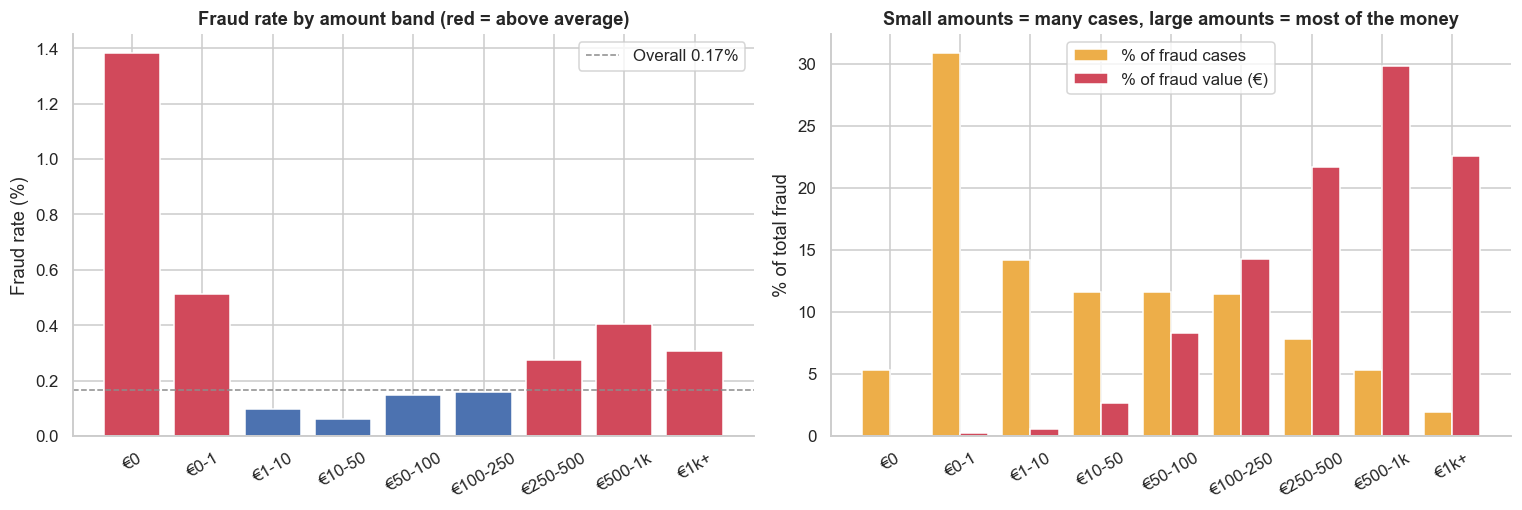

Transactions above €250 are 8.0% of volume but 74.0% of fraud losses.


In [72]:
fig, axes = plt.subplots(1, 2, figsize=(14, 4.8))

colors = [FRAUD_C if r > overall_rate else LEGIT_C for r in bands['Fraud_Rate_pct']]
axes[0].bar(bands.index.astype(str), bands['Fraud_Rate_pct'], color=colors)
axes[0].axhline(overall_rate, color=GREY_C, ls='--', lw=1, label=f'Overall {overall_rate:.2f}%')
axes[0].set_title('Fraud rate by amount band (red = above average)')
axes[0].set_ylabel('Fraud rate (%)'); axes[0].legend(); axes[0].tick_params(axis='x', rotation=30)

x = np.arange(len(bands)); w = 0.4
axes[1].bar(x - w/2, bands['Share_of_Fraud_Cases_pct'], w, color=ACCENT_C, label='% of fraud cases')
axes[1].bar(x + w/2, bands['Share_of_Fraud_Value_pct'], w, color=FRAUD_C, label='% of fraud value (€)')
axes[1].set_xticks(x); axes[1].set_xticklabels(bands.index.astype(str), rotation=30)
axes[1].set_title('Small amounts = many cases, large amounts = most of the money')
axes[1].set_ylabel('% of total fraud'); axes[1].legend()

plt.tight_layout(); save(fig, '04_amount_band_risk'); plt.show()

big = bands.loc[['€250-500', '€500-1k', '€1k+']]
print(f"Transactions above €250 are {big['Transactions'].sum() / len(df):.1%} of volume "
      f"but {big['Fraud_Value'].sum() / bands['Fraud_Value'].sum():.1%} of fraud losses.")

**Insight:** two very different risk profiles emerge:
1. **Micro transactions (≤ €1)** have one of the highest fraud *rates* and the largest number of cases, but tiny losses – they are an **early-warning signal** (card testing) rather than a cost driver.
2. **High-value transactions (> €250)** are a small slice of volume but account for the **majority of money lost**.

**Recommendation:** treat a micro "test" transaction as a trigger to monitor the card closely for the next few hours, and prioritise analyst time on high-value alerts where each catch saves the most money.

## 8. Q5 – Which columns look most different for fraud?

`V1`–`V28` are anonymized, but we can still compare **how differently each one behaves for fraud and legitimate transactions**. The chart uses a simple measure: the gap between the two averages, divided by the column's normal spread. The further from 0, the bigger the difference.


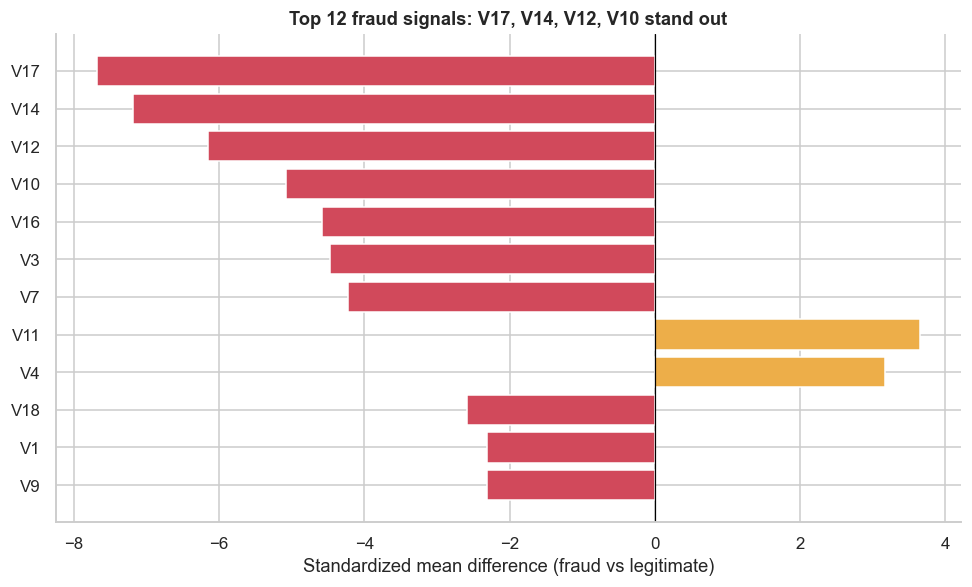

,Std_Mean_Diff,Direction
V17,-7.68,Lower in fraud
V14,-7.19,Lower in fraud
V12,-6.15,Lower in fraud
V10,-5.07,Lower in fraud
V16,-4.59,Lower in fraud
V3,-4.47,Lower in fraud
V7,-4.22,Lower in fraud
V11,3.65,Higher in fraud


In [76]:
features = [f'V{i}' for i in range(1, 29)] + ['Amount', 'Hour']
smd = ((fraud[features].mean() - legit[features].mean()) / df[features].std()).rename('Std_Mean_Diff')
signal = (pd.DataFrame(smd)
            .assign(Abs=lambda t: t['Std_Mean_Diff'].abs(),
                    Direction=lambda t: np.where(t['Std_Mean_Diff'] < 0, 'Lower in fraud', 'Higher in fraud'))
            .sort_values('Abs', ascending=False))

top = signal.head(12).iloc[::-1]
fig, ax = plt.subplots(figsize=(9, 5.5))
ax.barh(top.index, top['Std_Mean_Diff'], color=[FRAUD_C if v < 0 else ACCENT_C for v in top['Std_Mean_Diff']])
ax.axvline(0, color='black', lw=0.8)
ax.set_xlabel('Standardized mean difference (fraud vs legitimate)')
ax.set_title(f"Top 12 fraud signals: {', '.join(signal.index[:4])} stand out")
plt.tight_layout(); save(fig, '05_top_fraud_signals'); plt.show()

signal[['Std_Mean_Diff', 'Direction']].head(8)

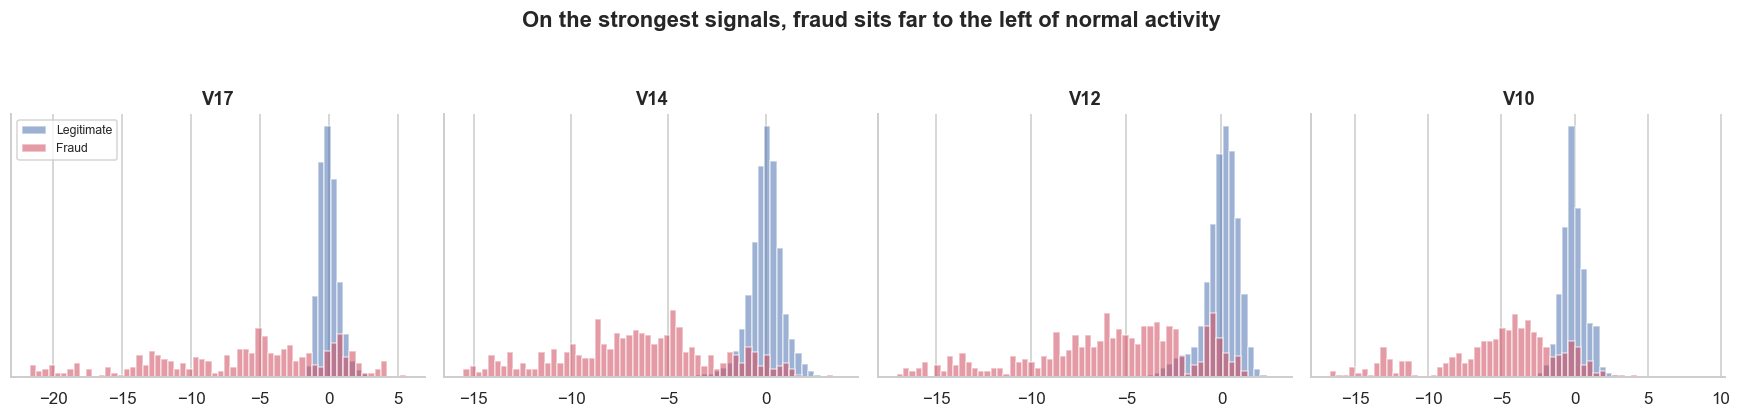

In [77]:
top4 = signal.index[:4].tolist()
fig, axes = plt.subplots(1, 4, figsize=(16, 3.6))
for ax, feat in zip(axes, top4):
    lo = min(fraud[feat].quantile(0.02), legit[feat].quantile(0.001))
    hi = max(fraud[feat].quantile(0.98), legit[feat].quantile(0.999))
    for label, color in [('Legitimate', LEGIT_C), ('Fraud', FRAUD_C)]:
        sub = df.loc[df['Label'] == label, feat]
        ax.hist(sub, bins=60, range=(lo, hi), density=True, alpha=0.55, color=color, label=label)
    ax.set_title(feat); ax.set_yticks([])
axes[0].legend(fontsize=8)
fig.suptitle('On the strongest signals, fraud sits far to the left of normal activity', fontweight='bold', y=1.05)
plt.tight_layout(); save(fig, '06_signal_distributions'); plt.show()

**Insight:** a few columns, led by `V17`, `V14`, `V12` and `V10`, look very different for fraud, which tends to sit at much lower values, although the two groups still overlap. `Amount` and `Hour` differ far less, so they are weak clues on their own. The names of these columns are hidden, so we can't explain them or write business rules from them, which is why the alert rules later in this notebook use hour and amount instead.


## 9. SQL Analysis

The same questions answered in **SQL**, as an analyst would against a transactions table in a data warehouse. The cleaned data is loaded into an in-memory SQLite database.

In [82]:
conn = sqlite3.connect(':memory:')
df.assign(Amount_Band=df['Amount_Band'].astype(str)).to_sql('transactions', conn, index=False)

def sql(query):
    return pd.read_sql_query(query, conn)

print('Table "transactions" loaded:', sql('SELECT COUNT(*) AS n FROM transactions')['n'][0], 'rows')

Table "transactions" loaded: 283726 rows


In [83]:
# KPI summary per day
sql('''
SELECT  Day,
        COUNT(*)                                        AS transactions,
        SUM(Class)                                      AS fraud_cases,
        ROUND(100.0 * SUM(Class) / COUNT(*), 3)         AS fraud_rate_pct,
        ROUND(SUM(Amount), 0)                           AS total_value,
        ROUND(SUM(CASE WHEN Class = 1 THEN Amount END), 0) AS fraud_value
FROM    transactions
GROUP BY Day
ORDER BY Day;
''')

,Day,transactions,fraud_cases,fraud_rate_pct,total_value,fraud_value
0,1,144236,272,0.19,"13,062,079.00","32,469.00"
1,2,139490,201,0.14,"12,039,923.00","26,122.00"


In [86]:
# Riskiest hours, with fraud rate relative to the overall average
sql('''
WITH hourly AS (
    SELECT Hour,
           COUNT(*)   AS transactions,
           SUM(Class) AS fraud_cases,
           1.0 * SUM(Class) / COUNT(*) AS fraud_rate
    FROM   transactions
    GROUP BY Hour
),
overall AS (SELECT 1.0 * SUM(Class) / COUNT(*) AS avg_rate FROM transactions)
SELECT  h.Hour,
        h.transactions,
        h.fraud_cases,
        ROUND(100 * h.fraud_rate, 3)          AS fraud_rate_pct,
        ROUND(h.fraud_rate / o.avg_rate, 1)   AS risk_index_vs_avg
FROM    hourly h CROSS JOIN overall o
ORDER BY h.fraud_rate DESC
LIMIT 6;
''')

,Hour,transactions,fraud_cases,fraud_rate_pct,risk_index_vs_avg
0,2,3308,48,1.45,8.70
1,4,2204,23,1.04,6.30
2,3,3487,17,0.49,2.90
3,5,2988,11,0.37,2.20
4,7,7233,23,0.32,1.90
5,11,16781,53,0.32,1.90


In [88]:
# Where does the money go? Fraud losses by amount band with running share
sql('''
WITH band AS (
    SELECT Amount_Band,
           MIN(Amount)                             AS band_min,
           SUM(Class)                              AS fraud_cases,
           SUM(CASE WHEN Class = 1 THEN Amount ELSE 0 END) AS fraud_value
    FROM   transactions
    GROUP BY Amount_Band
)
SELECT  Amount_Band,
        fraud_cases,
        ROUND(fraud_value, 0) AS fraud_value,
        ROUND(100.0 * fraud_value / SUM(fraud_value) OVER (), 1) AS pct_of_loss,
        ROUND(100.0 * SUM(fraud_value) OVER (ORDER BY band_min DESC) / SUM(fraud_value) OVER (), 1)
            AS cumulative_pct_from_top
FROM    band
ORDER BY band_min DESC;
''')

,Amount_Band,fraud_cases,fraud_value,pct_of_loss,cumulative_pct_from_top
0,€1k+,9,"13,237.00",22.60,22.60
1,€500-1k,25,"17,445.00",29.80,52.40
2,€250-500,37,"12,683.00",21.60,74.00
3,€100-250,54,"8,370.00",14.30,88.30
4,€50-100,55,"4,867.00",8.30,96.60
5,€10-50,55,"1,540.00",2.60,99.20
6,€1-10,67,318.00,0.50,99.80
7,€0-1,146,132.00,0.20,100.00
8,€0,25,0.00,0.00,100.00


## 10. Q6 – Which simple alert rule should a fraud team start with?

A fraud team can't check every transaction, so it needs simple rules that decide what to check. Using the patterns found above, we test six rules. For each one we ask:

- **How many checks** would it create?
- **How many checks** does it take to find one fraud? Fewer is better.
- **How much fraud money** does each check cover?


In [91]:
rules = sql('''
WITH rule_checks AS (
    SELECT 'Check everything' AS rule, Class, Amount FROM transactions
    UNION ALL
    SELECT 'Night hours', Class, Amount FROM transactions WHERE Hour BETWEEN 0 AND 6
    UNION ALL
    SELECT '€1 or less', Class, Amount FROM transactions WHERE Amount <= 1
    UNION ALL
    SELECT 'Over €250', Class, Amount FROM transactions WHERE Amount > 250
    UNION ALL
    SELECT 'Night + €1 or less', Class, Amount FROM transactions WHERE Hour BETWEEN 0 AND 6 AND Amount <= 1
    UNION ALL
    SELECT 'Night + over €250', Class, Amount FROM transactions WHERE Hour BETWEEN 0 AND 6 AND Amount > 250
)
SELECT  rule,
        COUNT(*)                                     AS checks,
        COUNT(*) / 2                                 AS checks_per_day,
        SUM(Class)                                   AS frauds_found,
        ROUND(100.0 * SUM(Class) / (SELECT SUM(Class) FROM transactions), 1) AS pct_of_frauds,
        ROUND(1.0 * COUNT(*) / SUM(Class), 0)        AS checks_per_fraud,
        ROUND(SUM(Class * Amount), 0)                AS fraud_money,
        ROUND(100.0 * SUM(Class * Amount) / (SELECT SUM(Class * Amount) FROM transactions), 1) AS pct_of_fraud_money,
        ROUND(SUM(Class * Amount) / COUNT(*), 2)     AS fraud_money_per_check
FROM    rule_checks
GROUP BY rule
ORDER BY checks_per_fraud DESC;
''')
rules

,rule,checks,checks_per_day,frauds_found,pct_of_frauds,checks_per_fraud,fraud_money,pct_of_fraud_money,fraud_money_per_check
0,Check everything,283726,141863,473,100.00,600.00,"58,591.00",100.00,0.21
1,Over €250,22571,11285,71,15.00,318.00,"43,365.00",74.00,1.92
2,Night hours,27924,13962,124,26.20,225.00,"11,059.00",18.90,0.40
3,€1 or less,30331,15165,171,36.20,177.00,132.00,0.20,0.00
4,Night + over €250,1409,704,12,2.50,117.00,"8,336.00",14.20,5.92
5,Night + €1 or less,3112,1556,64,13.50,49.00,54.00,0.10,0.02


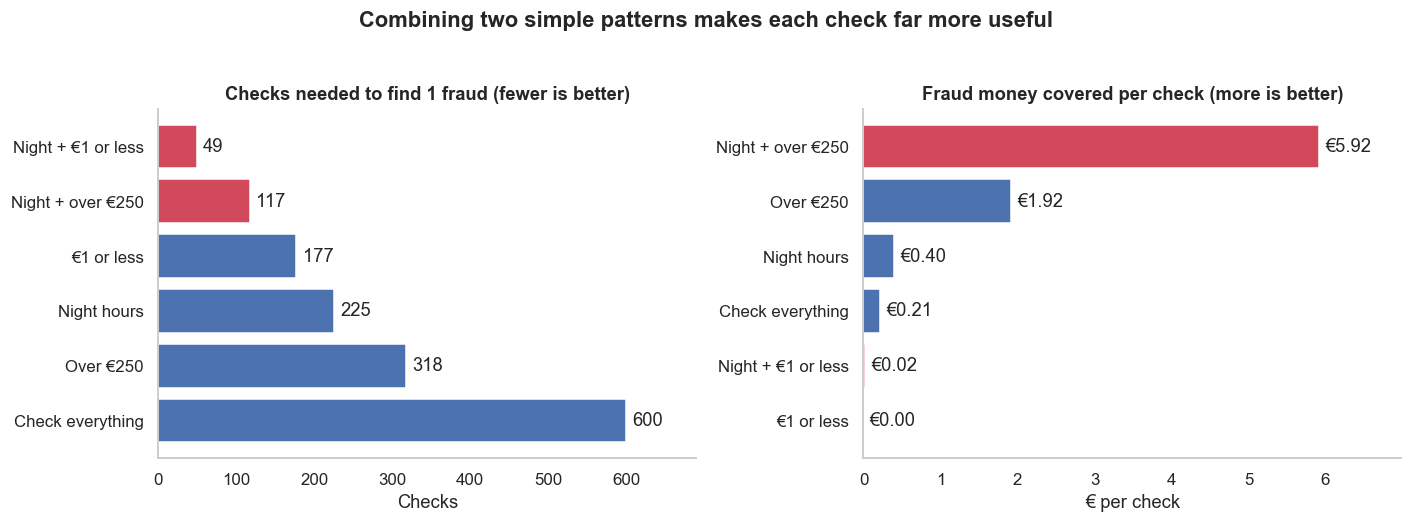

In [92]:
chosen = ['Night + €1 or less', 'Night + over €250']
fig, axes = plt.subplots(1, 2, figsize=(13, 4.6))

left = rules.sort_values('checks_per_fraud', ascending=False)
axes[0].barh(left['rule'], left['checks_per_fraud'], color=[FRAUD_C if r in chosen else LEGIT_C for r in left['rule']])
for i, v in enumerate(left['checks_per_fraud']):
    axes[0].text(v + 8, i, f'{v:,.0f}', va='center')
axes[0].set_title('Checks needed to find 1 fraud (fewer is better)')
axes[0].set_xlim(0, left['checks_per_fraud'].max() * 1.15)
axes[0].grid(False); axes[0].set_xlabel('Checks')

right = rules.sort_values('fraud_money_per_check')
axes[1].barh(right['rule'], right['fraud_money_per_check'], color=[FRAUD_C if r in chosen else LEGIT_C for r in right['rule']])
for i, v in enumerate(right['fraud_money_per_check']):
    axes[1].text(v + 0.08, i, f'€{v:.2f}', va='center')
axes[1].set_title('Fraud money covered per check (more is better)')
axes[1].set_xlim(0, right['fraud_money_per_check'].max() * 1.18)
axes[1].grid(False); axes[1].set_xlabel('€ per check')

fig.suptitle('Combining two simple patterns makes each check far more useful', fontweight='bold', y=1.03)
plt.tight_layout(); save(fig, '07_alert_rules'); plt.show()

**Insight:** no single rule does everything, because small frauds and big losses are different problems. The best choice depends on the goal:

| Goal | Rule to start with | Why |
|---|---|---|
| Spot stolen cards early | **Night + €1 or less** | Finds 1 fraud every 49 checks, about 12× better than checking at random (1 in 600) |
| Protect the most money per check | **Night + over €250** | Covers €5.92 of fraud per check, compared with €0.21 for checking everything |

**Decision:** start with these two rules. Together they create about **2,260 checks per day** at this dataset's volume, cover **76 frauds (16%)** and **€8,391 (14% of fraud money)**. The team should compare that with how many checks it can actually handle.

**What this does not solve:** these rules still miss most fraud, and "over €250" alone covers far more money (74%) but creates about 11,300 checks per day. Night + over €250 also rests on only 12 frauds, and the rules were chosen and measured on the same 2 days, so they need testing on new data before use.


## 11. Dashboard-Ready Exports

Summary tables are saved to `outputs/` so they can be loaded straight into **Tableau / Power BI / Excel** to build an interactive fraud dashboard.



In [97]:
hour_band = (df.assign(Fraud_Amount=df['Amount'] * df['Class'])
               .groupby(['Hour', 'Amount_Band'], observed=True)
               .agg(Transactions=('Class', 'size'), Fraud_Cases=('Class', 'sum'), Fraud_Value=('Fraud_Amount', 'sum'))
               .reset_index())
hour_band['Band_Order'] = hour_band['Amount_Band'].cat.codes + 1

exports = {
    'kpi_summary.csv'       : kpi_df.reset_index().rename(columns={'index': 'KPI'}),
    'fraud_by_hour.csv'     : hourly.reset_index(),
    'fraud_by_amount_band.csv': bands.reset_index(),
    'fraud_by_hour_band.csv': hour_band,
    'alert_rules.csv'       : rules,
}
for fname, table in exports.items():
    table.to_csv(f'outputs/{fname}', index=False)
    print(f'saved outputs/{fname:<28} {table.shape[0]:>3} rows')

conn.close()

saved outputs/kpi_summary.csv                9 rows
saved outputs/fraud_by_hour.csv             24 rows
saved outputs/fraud_by_amount_band.csv       9 rows
saved outputs/fraud_by_hour_band.csv       216 rows
saved outputs/alert_rules.csv                6 rows


## 12. Recommendations

| # | Recommendation | Evidence |
|---|---|---|
| 1 | **Automatically flag two types of night payment:** payments of €1 or less, which may be criminals testing stolen cards, and payments over €250, where each flag covers the most fraud money. Don't block them automatically, because most are genuine. Test asking customers to confirm them, with analysts reviewing suspicious cases. | About 98–99% of flagged payments are genuine, but these rules find fraud or cover money far better than checking everything (Section 10). |
| 2 | **Test tighter controls at night (00:00–06:59)** – lower alert thresholds or add step-up authentication. | Night-time fraud rate is several times the daytime rate (Section 6). |
| 3 | **Treat ≤ €1 transactions as a card-testing warning** and monitor the card for follow-up high-value attempts. | Micro transactions have one of the highest fraud rates (Sections 5 & 7). |
| 4 | **Prioritise high-value alerts** in the analyst queue. | Transactions > €250 carry most of the money lost (Section 7). |
| 5 | **Track a fraud KPI dashboard** (fraud rate, € lost, night-time share, high-value share) using the exported tables. | Section 11. |

## 13. Limitations & Next Steps

- **Anonymized features:** `V1`–`V28` can be compared but not explained or turned into business rules. Real fields such as merchant, country and channel would allow deeper analysis.
- **Short window:** only 2 days of data. No weekly/seasonal patterns and the hour-of-day is relative to the start of the recording.
- **Rules tested on the same data:** the alert rules were chosen and measured on the same 2 days data, so they need testing on new data.


*The dataset does not state its currency.* 

*Data: Machine Learning Group – ULB, [Kaggle Credit Card Fraud Detection](https://www.kaggle.com/datasets/mlg-ulb/creditcardfraud). Amounts are shown in € because the transactions were made by European cardholders.*